## SETUP

In [1]:
import os
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import confusion_matrix
import time

Columns with string values: Index([], dtype='object')
Columns with all zeros (representing 'unknown'):
Index(['original_firstorder_InterquartileRange',
       'original_firstorder_Kurtosis',
       'original_firstorder_MeanAbsoluteDeviation',
       'original_firstorder_Range',
       'original_firstorder_RobustMeanAbsoluteDeviation',
       'original_firstorder_Skewness', 'original_firstorder_Variance',
       'original_glcm_ClusterProminence', 'original_glcm_ClusterShade',
       'original_glcm_ClusterTendency', 'original_glcm_Contrast',
       'original_glcm_DifferenceAverage', 'original_glcm_DifferenceVariance',
       'original_glcm_Imc1', 'original_glcm_Imc2',
       'original_glcm_InverseVariance', 'original_glcm_SumSquares',
       'original_glrlm_GrayLevelVariance', 'original_glszm_GrayLevelVariance',
       'original_gldm_GrayLevelVariance'],
      dtype='object')
Selected Features: Index(['Nodule_id', 'Patient_id', 'Subtlety', 'Internalstructure',
       'Calcification', 'Sp

C:\Users\user\anaconda3\envs\new_env\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.659e+01, tolerance: 3.469e-02
  model = cd_fast.enet_coordinate_descent(


Index(['Nodule_id', 'Patient_id', 'Subtlety', 'Calcification', 'Margin',
       'Lobulation', 'Spiculation', 'original_shape_LeastAxisLength',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow', 'original_shape_MinorAxisLength',
       'original_shape_SurfaceArea', 'original_shape_VoxelVolume',
       'original_firstorder_Energy', 'original_firstorder_TotalEnergy',
       'original_glrlm_GrayLevelNonUniformity',
       'original_glrlm_LongRunEmphasis',
       'original_glrlm_LongRunHighGrayLevelEmphasis',
       'original_glrlm_LongRunLowGrayLevelEmphasis',
       'original_glrlm_RunLengthNonUniformity',
       'original_glszm_GrayLevelNonUniformity',
       'original_glszm_LargeAreaEmphasis',
       'original_glszm_LargeAreaHighGrayLevelEmphasis',
       'original_glszm_LargeAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneVariance', 'original_gldm_DependenceNonUniformity',
       'original_gldm_G

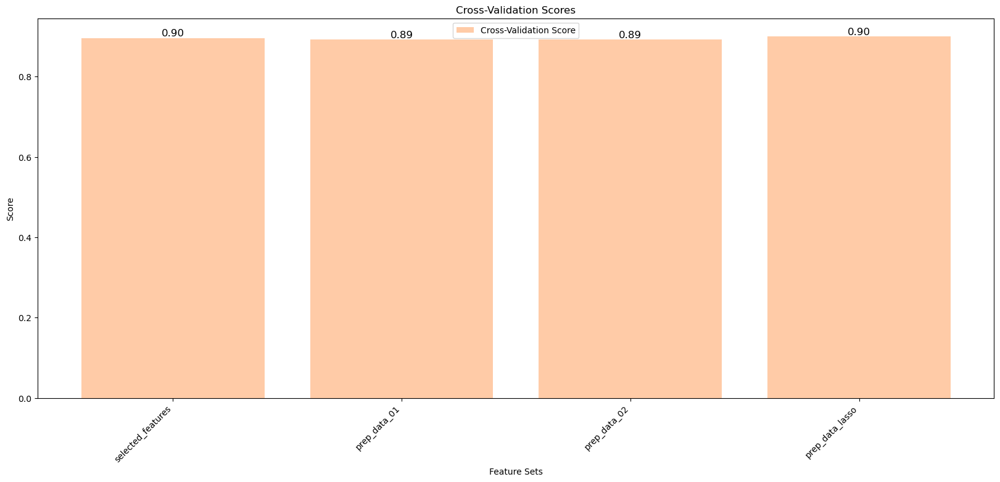

In [3]:
os.chdir(r'C:\Users\user\Desktop\PI_Code\Feature_Selection')
get_ipython().run_line_magic('run', 'feature_selection.ipynb')

## Crucial Functions

In [6]:
# Function that helps us to find the best k for accuracy between 1 and kmax
def find_k_knn(X, y, kmax):
    k_values = [i for i in range (1,kmax+1)]
    accuracies = []
    for k in k_values:
        model = KNeighborsClassifier(k)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        accuracies.append(accuracy)
    print(accuracies)

    #Ploting the results of Cross Validation
    sns.lineplot(x = k_values, y = accuracies, marker = 'o')
    plt.xlabel("K Values")
    plt.ylabel("Accuracy Score")
    plt.title('Knn performance')
    plt.grid(True)  # Add grid for better readability 

    best_index = np.argmax(accuracies)
    best_k = k_values[best_index]
    print(f'Best k = {best_k}')

In [8]:
# Function that helps us to find the best number of estimators for accuracy between 1 and numestimatorsmax
def find_est_rf(X, y, numestimatorsmax, random_state):
    numest = [i for i in range(1, numestimatorsmax+1, 10)]
    accuracies = []
    for est in numest:
        model = RandomForestClassifier(est)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        accuracies.append(accuracy)
    print(accuracies)
    
    sns.lineplot(x = numest, y = accuracies, marker = 'o')
    plt.xlabel("Nr of estimators")
    plt.ylabel("Accuracy Score")
    plt.title('RandomForest performance')
    plt.grid(True)  # Add grid for better readability 
    
    best_index = np.argmax(accuracies)
    best_est = numest[best_index]
    print(f'Best estimator = {best_est}')

In [10]:
# Function that builds the confusion matrix for a specific k value
def build_cm_knn(X, y, k):
    model = KNeighborsClassifier(k)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)

    plt.figure()
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title("Confusion Matrix")
    plt.colorbar()
    plt.ylabel('Real')
    plt.xlabel('Predict')
    plt.show()

In [53]:
# Function that builds the heatmap based on the confusion matrix for a specific k value
def build_heatmap_knn(X, y, k):
    model = KNeighborsClassifier(k)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")
    plt.xlabel('Predict')
    plt.ylabel('Real')
    plt.xticks([1, 0], ['Malignant', 'Begign'])
    plt.yticks([1, 0], ['Malignant', 'Begign'])
    plt.title('Confusion Matrix w/ values')
    plt.show()

In [55]:
# Function that prints the precision, recall and f1-score based on the confusion matrix for a specific k value
def show_stats_knn(k):
    model = KNeighborsClassifier(k)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    precision = precision_score(y_test, y_pred, average=None)
    recall = recall_score(y_test, y_pred, average=None)
    f1 = f1_score(y_test, y_pred, average=None)

    data = {'Feature Set': ['Malignant', 'Begign'],
            'Precision': precision,
            'Recall': recall,
            'F1-score': f1 }

    df = pd.DataFrame(data)
    print(df)

In [18]:
# Function that shows the training time of the dataset for a specific k value
def time_stats_knn(k):
    start_time = time.time()
    model = KNeighborsClassifier(k)
    model.fit(X_train, y_train)
    end_time = time.time()
    training_time = end_time - start_time
    print("processing time", training_time, "seconds")

In [20]:
# Function that builds the confusion matrix for a specific est value
def build_cm_rf(X, y, est):
    model = RandomForestClassifier(est)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)

    plt.figure()
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title("Confusion Matrix")
    plt.colorbar()
    plt.ylabel('Real')
    plt.xlabel('Predict')
    plt.show()

In [57]:
# Function that builds the heatmap based on the confusion matrix for a specific est value
def build_heatmap_rf(X, y, est):
    model = RandomForestClassifier(est)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")
    plt.xlabel('Predict')
    plt.ylabel('Real')
    plt.xticks([1, 0], ['Malignant', 'Begign'])
    plt.yticks([1, 0], ['Malignant', 'Begign'])
    plt.title('Confusion Matrix w/ values')
    plt.show()

In [59]:
# Function that prints the precision, recall and f1-score based on the confusion matrix for a specific est value
def show_stats_rf(est):
    model = RandomForestClassifier(est)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    precision = precision_score(y_test, y_pred, average=None)
    recall = recall_score(y_test, y_pred, average=None)
    f1 = f1_score(y_test, y_pred, average=None)

    data = {'Feature Set': ['Malignant','Begign'],
            'Precision': precision,
            'Recall': recall,
            
            'F1-score': f1 }

    df = pd.DataFrame(data)
    print(df)

In [26]:
# Function that shows the training time of the dataset for a specific est value
def time_stats_rf(est):
    start_time = time.time()
    model = RandomForestClassifier(est)
    model.fit(X_train, y_train)
    end_time = time.time()
    training_time = end_time - start_time
    print("processing time", training_time, "seconds")

In [28]:
# Function that builds the pairplot of the data
def build_pairplot(data, X):
    sns.pairplot(data, hue='Malignancy', vars=X)
    plt.title('Pairplot das Características por Classe')
    plt.show()

In [30]:
from sklearn.svm import SVC

# 1. Find the best C value for SVC
def find_c_svc(X, y, c_values):
    accuracies = []
    for C in c_values:
        model = SVC(C=C, kernel='rbf')  # using RBF kernel by default
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        accuracies.append(accuracy)

    print(accuracies)

    sns.lineplot(x=c_values, y=accuracies, marker='o')
    plt.xlabel("C Values")
    plt.ylabel("Accuracy Score")
    plt.title("SVC performance")
    plt.grid(True)

    best_index = np.argmax(accuracies)
    best_c = c_values[best_index]
    print(f'Best C = {best_c}')

In [32]:

# 2. Build confusion matrix
def build_cm_svc(X, y, C):
    model = SVC(C=C, kernel='rbf')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)

    plt.figure()
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title("Confusion Matrix")
    plt.colorbar()
    plt.ylabel('Real')
    plt.xlabel('Predict')
    plt.show()


In [61]:

# 3. Build heatmap
def build_heatmap_svc(X, y, C):
    model = SVC(C=C, kernel='rbf')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")
    plt.xlabel('Predict')
    plt.ylabel('Real')
    plt.xticks([1, 0], ['Malignant', 'Begign'])
    plt.yticks([1, 0], ['Malignant', 'Begign'])
    plt.title('Confusion Matrix w/ values')
    plt.show()


In [63]:
# 4. Show precision, recall, f1
def show_stats_svc(C):
    model = SVC(C=C, kernel='rbf')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    precision = precision_score(y_test, y_pred, average=None)
    recall = recall_score(y_test, y_pred, average=None)
    f1 = f1_score(y_test, y_pred, average=None)

    data = {'Feature Set': ['Malignant','Begign'],
            'Precision': precision,
            'Recall': recall,
            'F1-score': f1 }

    df = pd.DataFrame(data)
    print(df)


In [38]:
# 5. Training time
def time_stats_svc(C):
    start_time = time.time()
    model = SVC(C=C, kernel='rbf')
    model.fit(X_train, y_train)
    end_time = time.time()
    training_time = end_time - start_time
    print("processing time ", training_time, "seconds")


# Training Models

After seeing the cross-validation scores of each features set, we chose  to train with  Lasso features and selected_features

We will be traininig the dataset with KNN and RandomForest ans SVC and collect some statistics, such as:
- features pairplots;
- accuracy graphics;
- confusion matrices;
- heatmap based on the confusion matrices;
- precision, recall and f1-score values;
- Train time.

## RFE features 

In [80]:
X = prep_data[selected_features]
y = prep_data['Malignancy']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

In [ ]:
build_pairplot(low_2d_sd, X)#it tales forever

[0.8523076923076923, 0.84, 0.8338461538461538, 0.84, 0.8461538461538461, 0.8553846153846154, 0.8584615384615385, 0.8615384615384616, 0.8492307692307692, 0.8646153846153846, 0.8646153846153846, 0.8707692307692307, 0.8676923076923077, 0.8676923076923077, 0.8615384615384616, 0.8646153846153846, 0.8646153846153846, 0.8676923076923077, 0.8676923076923077, 0.8646153846153846]
Best k = 12


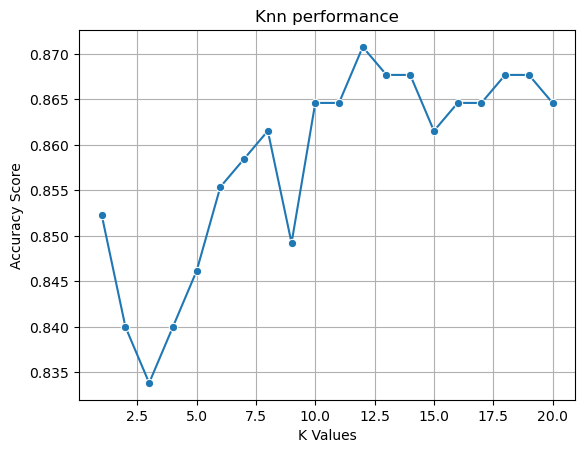

In [82]:
find_k_knn(X, y, 20)

processing time 0.011034488677978516 seconds
  Feature Set  Precision    Recall  F1-score
0   Malignant   0.892857  0.937500  0.914634
1      Begign   0.794521  0.682353  0.734177
Confusion Matrix:
 [[225  15]
 [ 27  58]]


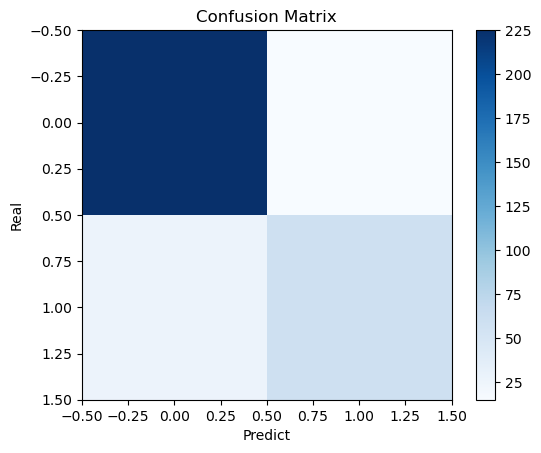

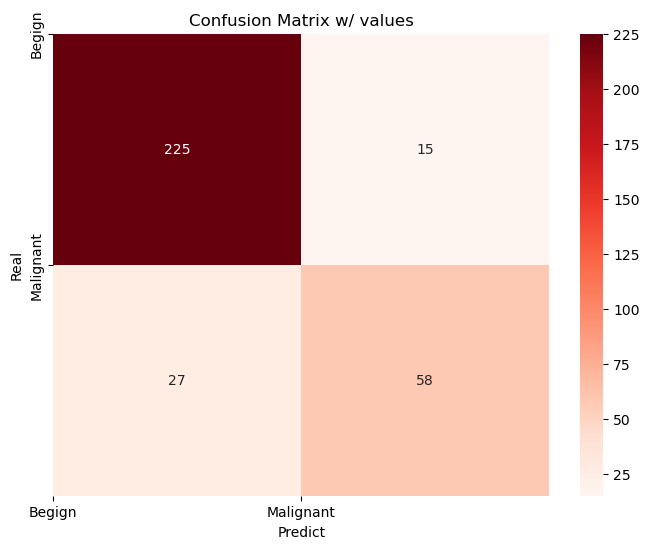

In [84]:
k = 12
time_stats_knn(k)
show_stats_knn(k)
build_cm_knn(X, y, k)
build_heatmap_knn(X, y, k)

### With RandomForest

[0.8184615384615385, 0.8769230769230769, 0.8830769230769231, 0.8738461538461538, 0.8769230769230769, 0.8892307692307693, 0.8769230769230769, 0.8892307692307693, 0.88, 0.8830769230769231, 0.8923076923076924, 0.8861538461538462, 0.88, 0.8676923076923077, 0.88, 0.8861538461538462, 0.8861538461538462, 0.8830769230769231, 0.8861538461538462, 0.8769230769230769]
Best estimator = 101


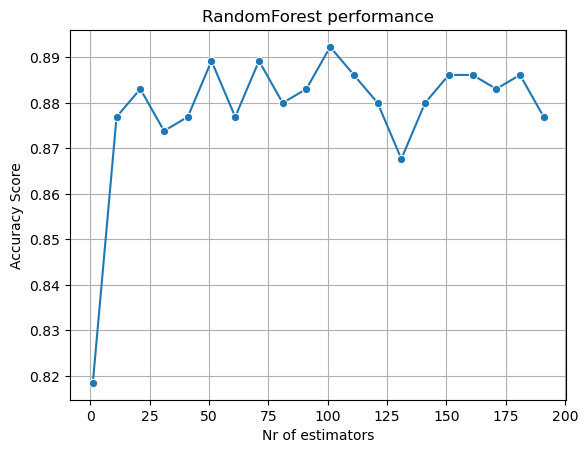

In [88]:
find_est_rf(X,y, 200, 42)

Confusion Matrix:
 [[223  17]
 [ 24  61]]


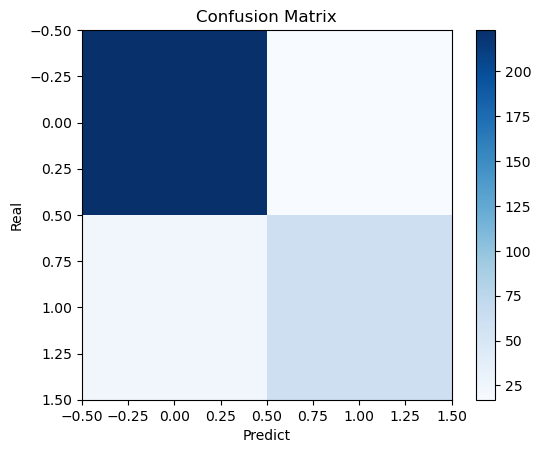

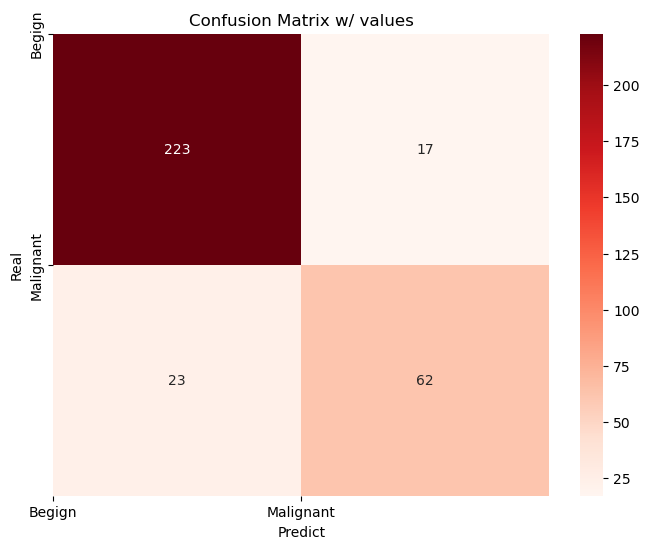

  Feature Set  Precision    Recall  F1-score
0   Malignant   0.906504  0.929167  0.917695
1      Begign   0.784810  0.729412  0.756098
processing time 2.8882172107696533 seconds


In [92]:
est = 101
build_cm_rf(X,y, est)
build_heatmap_rf(X,y, est)
show_stats_rf(est)
time_stats_rf(est)

### With SVC

[0.8184615384615385, 0.8523076923076923, 0.8646153846153846, 0.8646153846153846, 0.8707692307692307]
Best C = 100


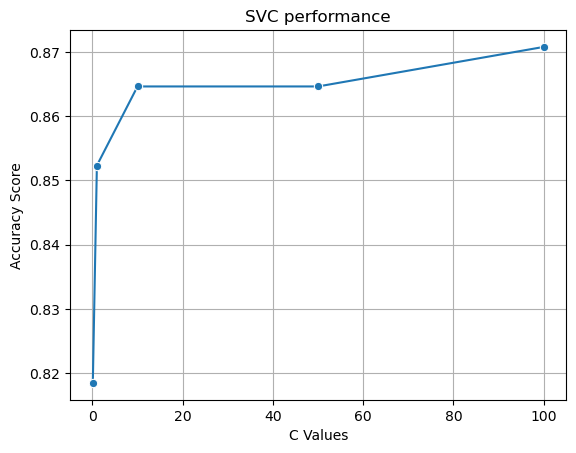

In [96]:
# Find best C for SVC
c_values = [0.1, 1, 10, 50, 100]
find_c_svc(X,y, c_values)


Confusion Matrix:
 [[227  13]
 [ 29  56]]


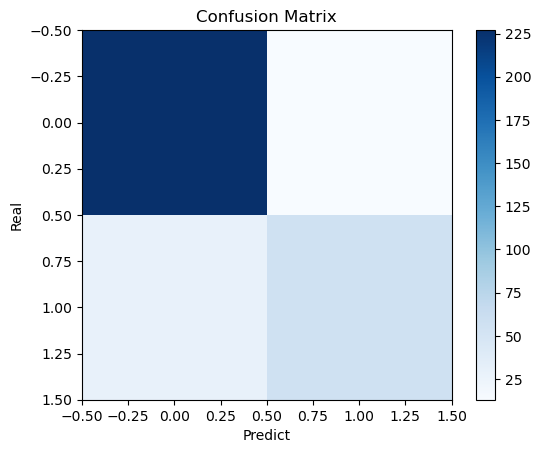

In [98]:
best_c = 100

#  Build confusion matrix
build_cm_svc(X, y, best_c)

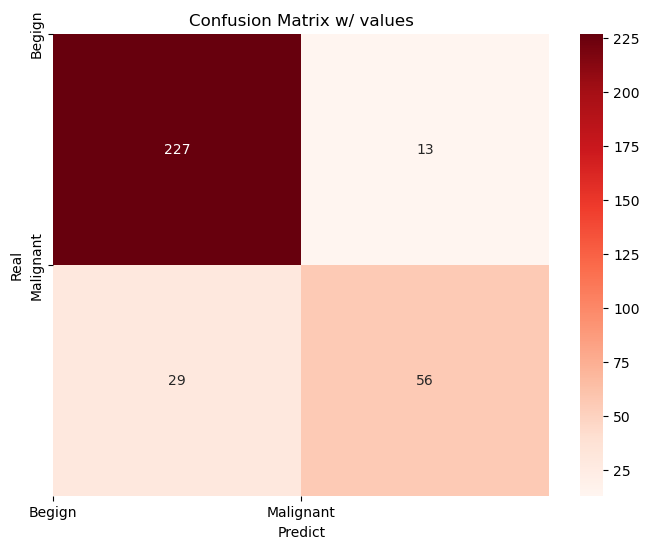

In [102]:
# Heatmap
build_heatmap_svc(X,y, best_c)

In [104]:
#  Precision, recall, F1-score
show_stats_svc(best_c)


  Feature Set  Precision    Recall  F1-score
0   Malignant   0.886719  0.945833  0.915323
1      Begign   0.811594  0.658824  0.727273


In [106]:
# Training time
time_stats_svc(best_c)

processing time  0.16840600967407227 seconds


In [118]:
X = medium_2d_sd[medium_tree_02]
y = medium_2d_sd['Malignancy']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

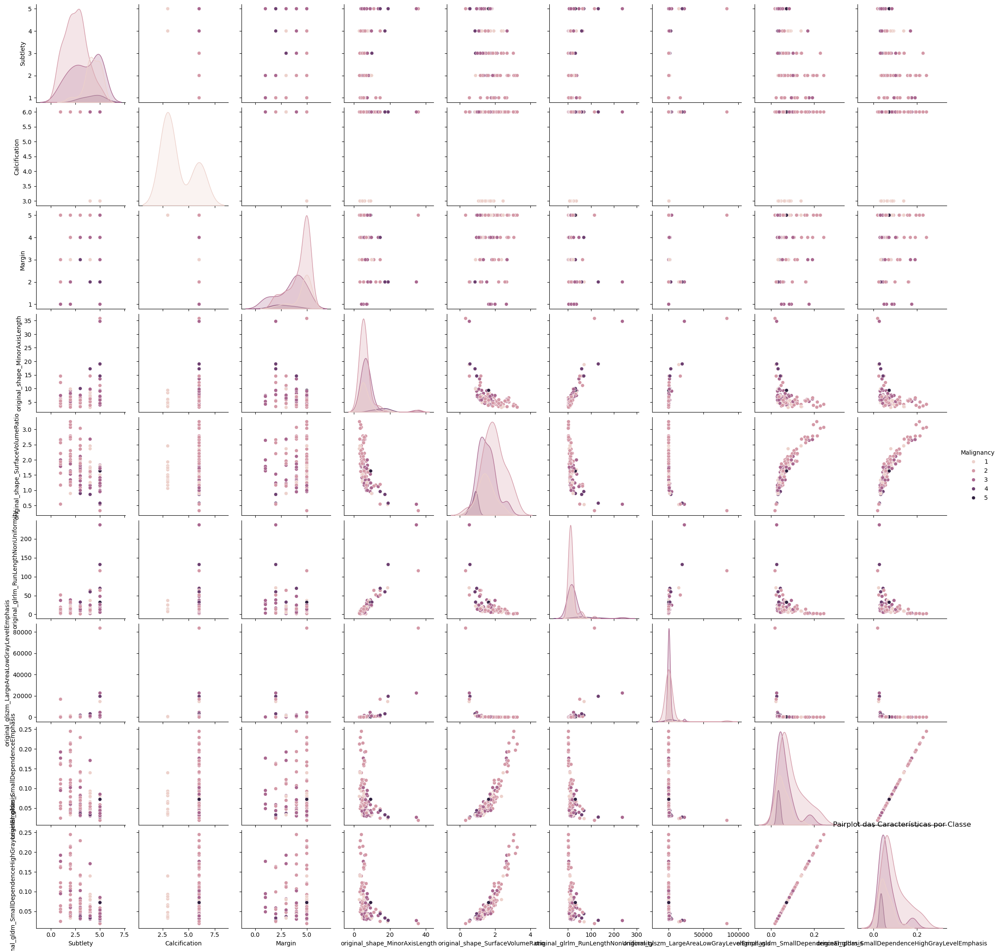

In [36]:
build_pairplot(medium_2d_sd, X)

### With KNN

[0.5833333333333334, 0.5416666666666666, 0.6041666666666666, 0.625, 0.5625, 0.5833333333333334, 0.625, 0.6041666666666666, 0.6041666666666666, 0.5833333333333334, 0.5833333333333334, 0.5625, 0.5416666666666666, 0.5625, 0.5416666666666666, 0.4791666666666667, 0.5625, 0.5625, 0.5416666666666666, 0.5]
Best k = 4


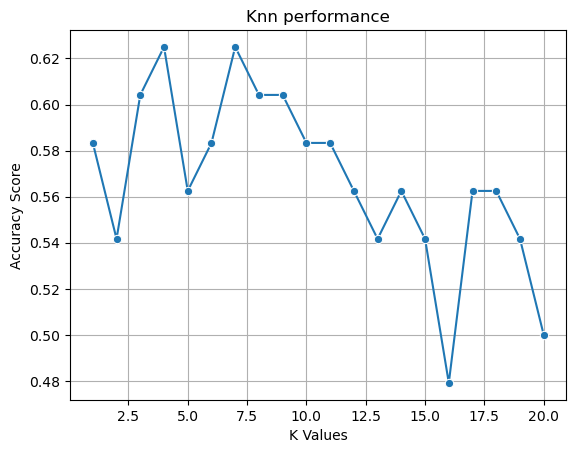

In [120]:
find_k_knn(X, y, 20)

processing time 0.015162229537963867 seconds
             Feature Set  Precision    Recall  F1-score
0        Highly unlikely   0.500000  0.600000  0.545455
1    Moderately unlikely   0.666667  0.833333  0.740741
2          Indeterminate   0.700000  0.411765  0.518519
3  Moderately Suspicious   0.000000  0.000000  0.000000
Confusion Matrix:
 [[ 3  1  0  1]
 [ 2 20  2  0]
 [ 0  9  7  1]
 [ 1  0  1  0]]


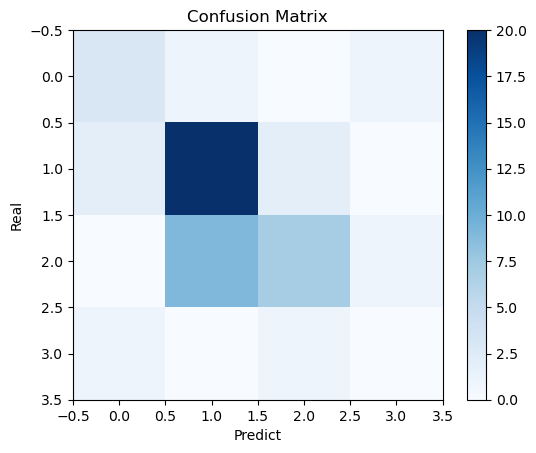

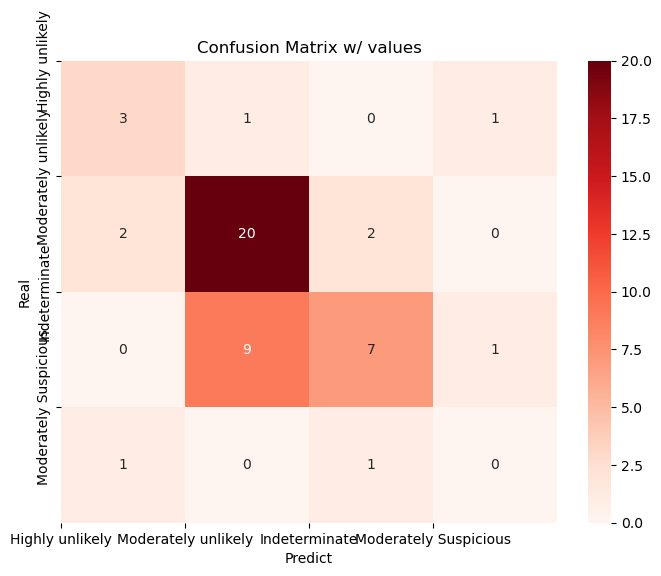

In [122]:
k = 4
time_stats_knn(k)
show_stats_knn(k)
build_cm_knn(X, y, k)
build_heatmap_knn(X, y, k)

### With RandomForest

[0.5833333333333334, 0.6041666666666666, 0.6666666666666666, 0.6458333333333334, 0.6666666666666666, 0.6458333333333334, 0.7083333333333334, 0.6666666666666666, 0.6875, 0.6875, 0.6458333333333334, 0.6666666666666666, 0.7291666666666666, 0.6666666666666666, 0.6875, 0.6458333333333334, 0.7083333333333334, 0.6875, 0.7083333333333334, 0.6875]
Best estimator = 121


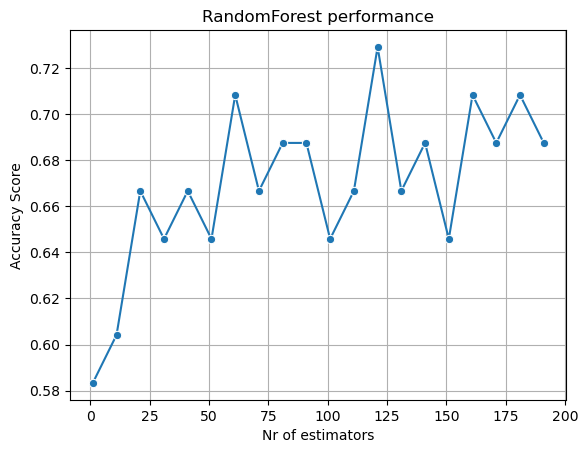

In [124]:
find_est_rf(X, y, 200, 42)

Confusion Matrix:
 [[ 4  1  0  0]
 [ 1 22  1  0]
 [ 0 11  6  0]
 [ 0  1  1  0]]


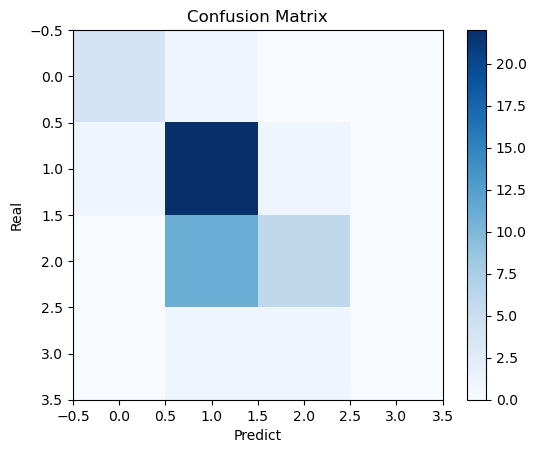

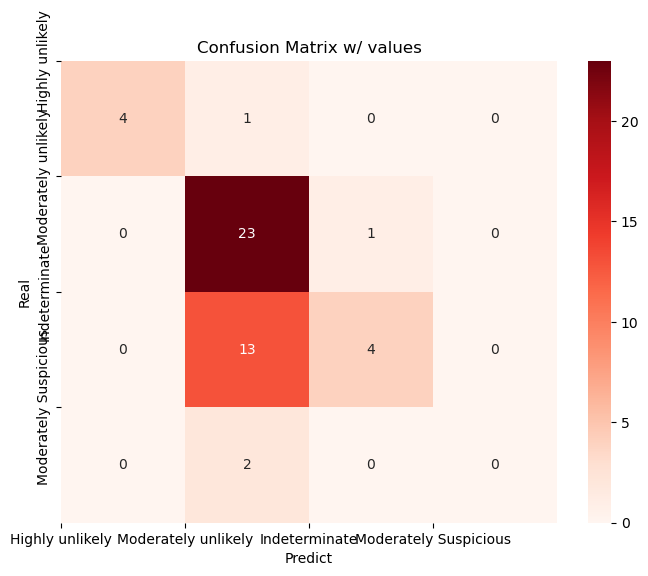

             Feature Set  Precision    Recall  F1-score
0        Highly unlikely   0.800000  0.800000  0.800000
1    Moderately unlikely   0.666667  0.916667  0.771930
2          Indeterminate   0.800000  0.470588  0.592593
3  Moderately Suspicious   0.000000  0.000000  0.000000
processing time 0.15635323524475098 seconds


C:\Users\user\anaconda3\envs\new_env\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [126]:
est = 121
build_cm_rf(X, y, est)
build_heatmap_rf(X, y, est)
show_stats_rf(est)
time_stats_rf(est)

### With SVC

[0.5, 0.5, 0.5, 0.5208333333333334, 0.5208333333333334, 0.5208333333333334, 0.5208333333333334, 0.5208333333333334, 0.5208333333333334, 0.5, 0.5208333333333334, 0.5208333333333334, 0.5208333333333334]
Best C = 0.5


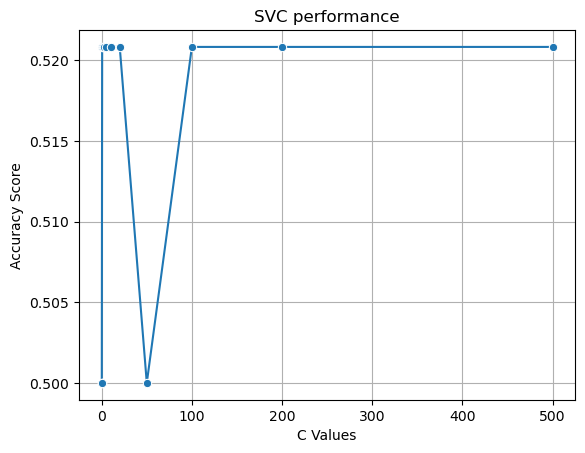

In [128]:
# Find best C for SVC
c_values = [0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500]
find_c_svc(X, y, c_values)


Confusion Matrix:
 [[ 0  4  1  0]
 [ 0 24  0  0]
 [ 0 16  1  0]
 [ 0  2  0  0]]


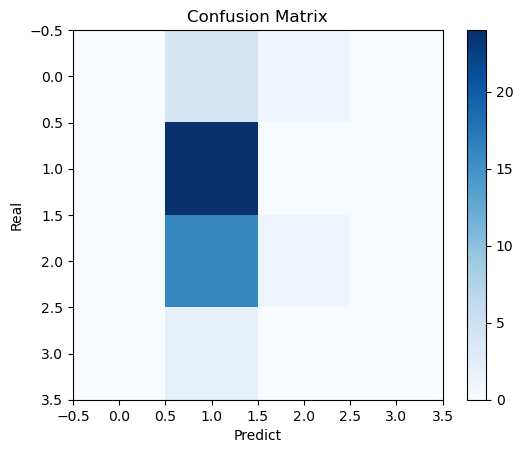

In [130]:
# Let's say best C was 1 (replace with your actual best one after running)
best_c = 0.5

# Build confusion matrix
build_cm_svc(X, y, best_c)

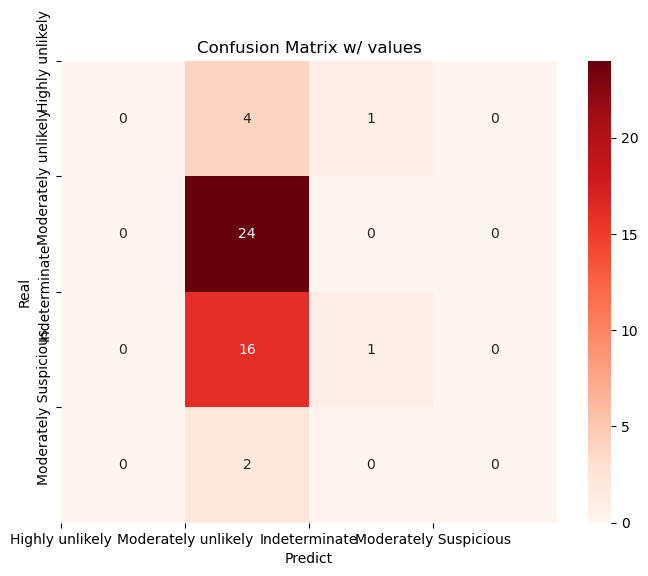

In [132]:
# Heatmap
build_heatmap_svc(X, y, best_c)

In [134]:
# Precision, recall, F1-score
show_stats_svc(best_c)


             Feature Set  Precision    Recall  F1-score
0        Highly unlikely   0.000000  0.000000  0.000000
1    Moderately unlikely   0.521739  1.000000  0.685714
2          Indeterminate   0.500000  0.058824  0.105263
3  Moderately Suspicious   0.000000  0.000000  0.000000


C:\Users\user\anaconda3\envs\new_env\lib\site-packages\sklearn\metrics\_classification.py:1471: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [99]:
# Training time
time_stats_svc(best_c)

processing time  0.004830837249755859 seconds


## Lasso features 

In [43]:
X = prep_data[prep_data_lasso]
y = prep_data['Malignancy']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

In [49]:
build_pairplot(high_2d_sd, X)#do not run this again it takes foreverrrrr !!!!

### With KNN

[0.8523076923076923, 0.84, 0.8338461538461538, 0.84, 0.8461538461538461, 0.8553846153846154, 0.8584615384615385, 0.8615384615384616, 0.8492307692307692, 0.8646153846153846, 0.8646153846153846, 0.8707692307692307, 0.8676923076923077, 0.8676923076923077, 0.8615384615384616, 0.8646153846153846, 0.8646153846153846, 0.8676923076923077, 0.8676923076923077, 0.8646153846153846]
Best k = 12


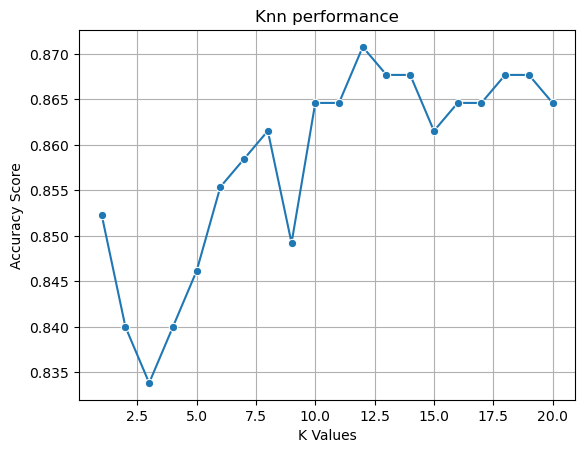

In [45]:
find_k_knn(X, y, 20)

processing time 0.007039785385131836 seconds
  Feature Set  Precision    Recall  F1-score
0   Malignant   0.892857  0.937500  0.914634
1      Begign   0.794521  0.682353  0.734177
Confusion Matrix:
 [[225  15]
 [ 27  58]]


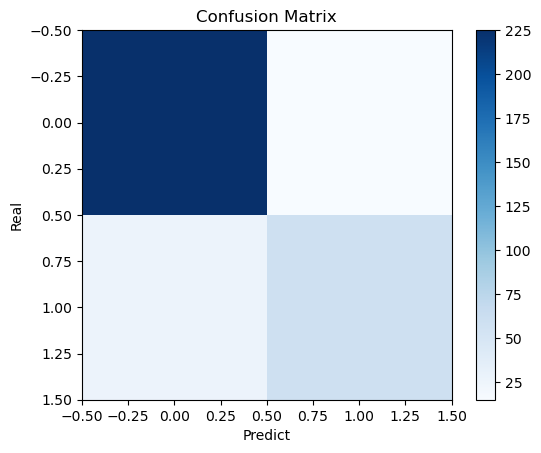

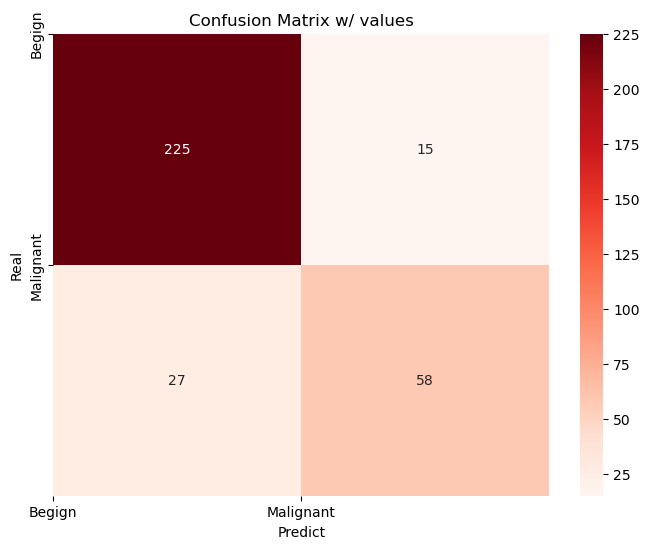

In [65]:
k = 12
time_stats_knn(k)
show_stats_knn(k)
build_cm_knn(X, y, k)
build_heatmap_knn(X, y, k)

### With RandomForest

[0.8184615384615385, 0.8707692307692307, 0.8830769230769231, 0.8830769230769231, 0.8769230769230769, 0.8861538461538462, 0.8738461538461538, 0.88, 0.8830769230769231, 0.8830769230769231, 0.8769230769230769, 0.8892307692307693, 0.88, 0.88, 0.8830769230769231, 0.8861538461538462, 0.8738461538461538, 0.8830769230769231, 0.8830769230769231, 0.8861538461538462]
Best estimator = 111


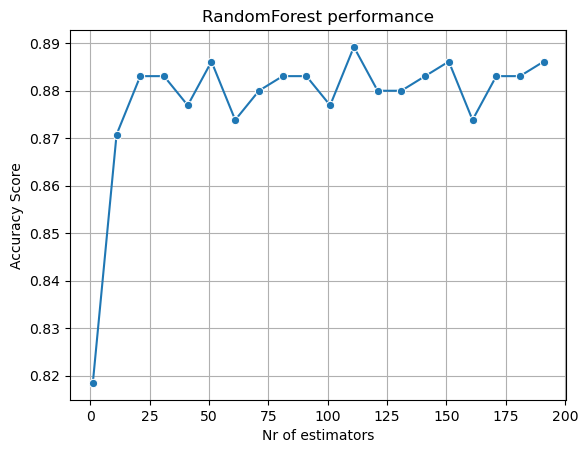

In [49]:
find_est_rf(X, y, 200, 42)

Confusion Matrix:
 [[225  15]
 [ 21  64]]


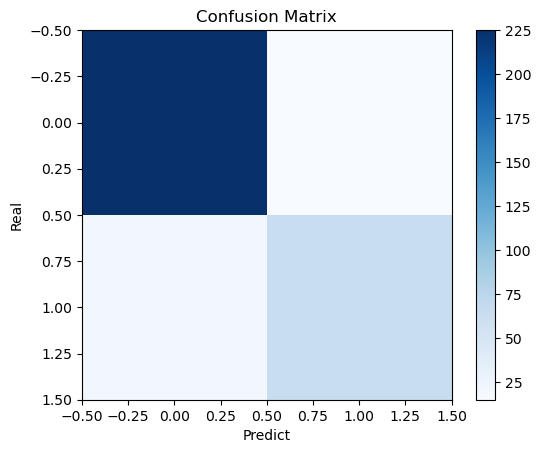

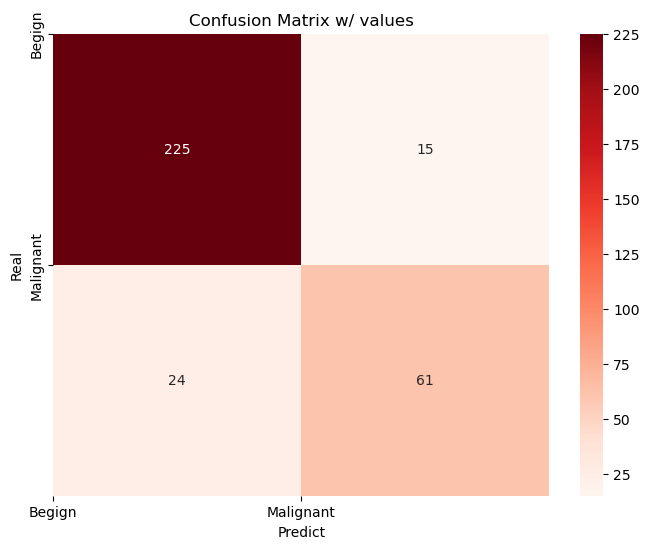

  Feature Set  Precision    Recall  F1-score
0   Malignant   0.904000  0.941667  0.922449
1      Begign   0.813333  0.717647  0.762500
processing time 2.457388401031494 seconds


In [67]:
est = 111
build_cm_rf(X, y, est)
build_heatmap_rf(X, y, est)
show_stats_rf(est)
time_stats_rf(est)

### With SVC

[0.7384615384615385, 0.7753846153846153, 0.8184615384615385, 0.8523076923076923, 0.8523076923076923, 0.8584615384615385, 0.8615384615384616, 0.8646153846153846, 0.8707692307692307, 0.8646153846153846, 0.8707692307692307, 0.8615384615384616, 0.8584615384615385]
Best C = 20


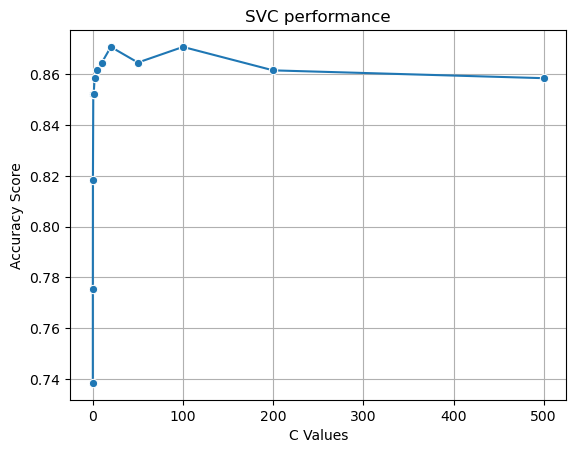

In [69]:
#  Find best C for SVC
c_values = [0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500]
find_c_svc(X, y, c_values)

Confusion Matrix:
 [[226  14]
 [ 28  57]]


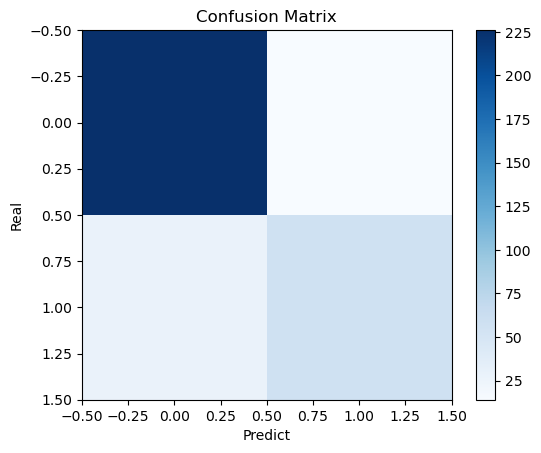

In [71]:
# Let's say best C turns out to be 2 (replace after testing)
best_c = 20

#  Build confusion matrix
build_cm_svc(X, y, best_c)

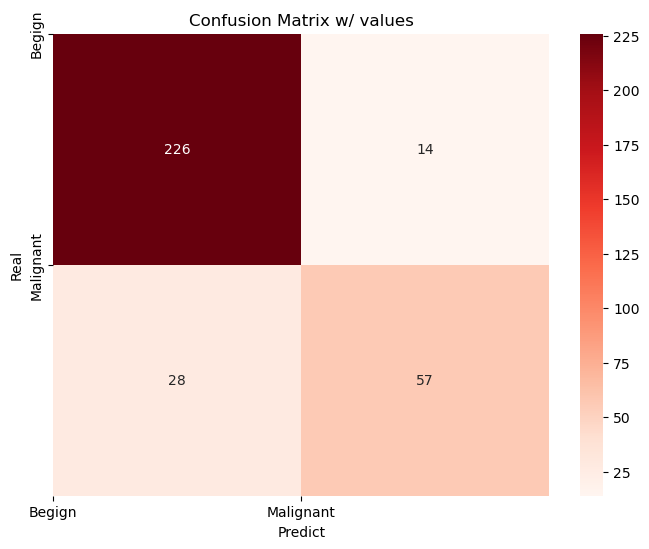

In [73]:
#  Heatmap
build_heatmap_svc(X, y, best_c)

In [75]:
#  Precision, recall, F1-score
show_stats_svc(best_c)

  Feature Set  Precision    Recall  F1-score
0   Malignant   0.889764  0.941667  0.914980
1      Begign   0.802817  0.670588  0.730769


In [77]:
# Training time
time_stats_svc(best_c)

processing time  0.11677241325378418 seconds


# Conclusions

In [112]:
import pandas as pd

# Example accuracy values — replace with your real values
lasso_knn = {0: 0.89, 1: 0.79}
lasso_rf = {0: 0.90, 1: 0.81}
lasso_svc = {0: 0.94, 1: 0.67}

rf_knn = {0: 0.89, 1: 0.79}
rf_rf = {0: 0.90, 1: 0.78}
rf_svc = {0: 0.86, 1: 0.81}

# Create the DataFrame
data = {
    "Model": ["LASSO", "", "RF", ""],
    "Class": [0, 1, 0, 1],
    "KNN Accuracy": [lasso_knn[0], lasso_knn[1], rf_knn[0], rf_knn[1]],
    "RF Accuracy": [lasso_rf[0], lasso_rf[1], rf_rf[0], rf_rf[1]],
    "SVC Accuracy": [lasso_svc[0], lasso_svc[1], rf_svc[0], rf_svc[1]],
}

df = pd.DataFrame(data)

# Display as a clean table
print(df.to_string(index=False))


Model  Class  KNN Accuracy  RF Accuracy  SVC Accuracy
LASSO      0          0.89         0.90          0.94
           1          0.79         0.81          0.67
   RF      0          0.89         0.90          0.86
           1          0.79         0.78          0.81


As we can see, the RandomForest had a better performance on the 3 feature sets when compared to KNN and SVC.
We can also conclude that the feature selection "LASSO" had the best performance, since it had a good accuracy in both of the methods used.

# SAVING THE BEST MODEL (RF WITH LASSO)

In [119]:
from sklearn.ensemble import RandomForestClassifier
import joblib

# Re-train only if you haven't saved the model object
rf_model = RandomForestClassifier(n_estimators=est, random_state=42)
rf_model.fit(X, y)

# Save the trained model
joblib.dump(rf_model, "rf_lasso_model.pkl")
print("✅ Random Forest model with LASSO-selected features saved!")


✅ Random Forest model with LASSO-selected features saved!


In [123]:
rf_model = joblib.load("rf_lasso_model.pkl")